# Представления текстов отзывов Amazon: TF-IDF, Word2Vec и Sentence-Transformers

Исследование DataForge сравнивает три способа представления текстов тональности
отзывов Amazon Reviews Polarity: разреженный TF-IDF, усредненные статические
эмбеддинги Word2Vec и сиамские предложения Sentence-BERT (MiniLM). На всех
представлениях обучается одна и та же логистическая регрессия, что позволяет
оценить вклад самого представления, а не классификатора.

**Задача.** Бинарная классификация тональности отзыва (0 — негативный, 1 — позитивный).

**Источник данных.** [fancyzhx/amazon_polarity](https://huggingface.co/datasets/fancyzhx/amazon_polarity),
официальные сплиты train (3 600 000 строк) и test (400 000 строк), поля `title`, `content`, `label`.
Фиксируется конкретная ревизия датасета и идентификаторы выбранных строк.

**Ограничения и допущения.**
- Работа ведется на воспроизводимом подмножестве (8 000 train + 2 000 test, сбалансированно, seed 42); метрики относятся к этому подмножеству, а не к полному датасету.
- Модели эмбеддингов используются без дообучения (transfer learning как есть).
- MiniLM обрезает тексты до 256 wordpiece-токенов, поэтому часть длинных отзывов представлена неполностью (доля обрезки измеряется ниже).
- Тональность определяется по паре «заголовок + текст», домен — отзывы магазинов Amazon.

## Содержание

1. [Окружение и подготовка](#sec-1)
2. [Обзор данных](#sec-2)
3. [Очистка и разбиение](#sec-3)
4. [TF-IDF](#sec-4)
5. [Word2Vec Google News](#sec-5)
6. [Sentence-Transformers MiniLM](#sec-6)
7. [Сравнение методов и итоговое тестирование](#sec-7)
8. [Проекции представлений: PCA, t-SNE, UMAP](#sec-8)
9. [Сохранение результатов и выводы](#sec-9)

## 1. Окружение и подготовка <a id="sec-1"></a>

Фиксируем seed 42 для воспроизводимости, определяем пути к данным и моделям,
выводим версии библиотек. Для SentenceTransformer используется GPU, если он доступен.

In [1]:
import gc
import hashlib
import json
import platform
import random
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import transformers
import sentence_transformers
import gensim
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.dpi"] = 110

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW_DIR = ROOT / "data" / "raw"
PROC_DIR = ROOT / "data" / "processed"
MODELS_DIR = ROOT / "models"
PROC_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

versions = pd.DataFrame(
    {"версия": [platform.python_version(), np.__version__, pd.__version__, sklearn.__version__,
                torch.__version__, transformers.__version__, sentence_transformers.__version__,
                gensim.__version__]},
    index=["python", "numpy", "pandas", "scikit-learn", "torch", "transformers",
           "sentence-transformers", "gensim"],
)
display(versions)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Устройство для кодирования предложений:", DEVICE)

/home/vaiforic/orca/workspaces/dataforge/bulb-NeNet-and-modern-approaches/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,версия
python,3.14.7
numpy,2.5.4
pandas,2.3.3
scikit-learn,1.7.2
torch,2.15.0+cpu
transformers,5.22.2
sentence-transformers,6.2.0
gensim,4.4.0


Устройство для кодирования предложений: cpu


## 2. Обзор данных <a id="sec-2"></a>

Подмножество подготовлено заранее из официальных Parquet-шардов датасета и сохранено в
`data/raw/amazon_polarity_sample.parquet`: 8 000 строк официального train (по 4 000 на класс)
и 2 000 строк официального test (по 1 000 на класс), выбор seed 42, идентификаторы исходных
строк `source_row` и хэши нормализованных текстов `text_sha256`. Файл и его метаданные
хранятся под контролем DVC. Ниже загружается готовая подвыборка; перед запуском она
должна быть получена из DVC (инструкции в README).


In [2]:
SOURCE_REPO = "fancyzhx/amazon_polarity"
SOURCE_REVISION = "9d9c45c18f8c3cf1b23a3c27917b60cbf28f3289"
SAMPLE_PATH = RAW_DIR / "amazon_polarity_sample.parquet"
SAMPLE_META_PATH = RAW_DIR / "amazon_polarity_sample.metadata.json"


def join_text(title, content):
    # Заголовок и текст объединяются как есть, с обычной пунктуацией и структурой
    return (str(title or "") + "\n" + str(content or "")).strip()


def normalize_text(text):
    return re.sub(r"\s+", " ", text).casefold().strip()


sample = pd.read_parquet(SAMPLE_PATH)
print("Выборка загружена из файла:", SAMPLE_PATH)

meta = json.loads(SAMPLE_META_PATH.read_text()) if SAMPLE_META_PATH.exists() else {}
print("Источник:", meta.get("source", SOURCE_REPO))
print("Ревизия датасета:", meta.get("revision", SOURCE_REVISION))
print("Seed выбора:", meta.get("seed", SEED))
display(sample.head(3))

Выборка загружена из файла: /home/vaiforic/orca/workspaces/dataforge/bulb-NeNet-and-modern-approaches/data/raw/amazon_polarity_sample.parquet
Источник: fancyzhx/amazon_polarity
Ревизия датасета: 9d9c45c18f8c3cf1b23a3c27917b60cbf28f3289
Seed выбора: 42


,title,content,label,source_split,source_row,text_sha256
0,The Worst!,A complete waste of time. Typographical errors...,0,train,10,dd4d0c6a6dbc67893a3b3d440c0f6833849164a49bf9d2...
1,Seek no further if you love melancholy music!,"This is it. The best, most heartfelt debut I'v...",1,train,1430,5149cfbd6fc3a310995a0d03e521ff1baf18085e6a26a0...
2,After the Fire,"I could hardly put ""After the Fire"" aside once...",1,train,1679,6ddf4c2379cbf63fe7c6662cb80eed92b3868b5c004f0c...


In [3]:
exclusion_rows = []
for part in meta.get("splits", []):
    ex = part.get("excluded_candidates", {})
    exclusion_rows.append({
        "официальный сплит": part.get("source_split"),
        "строк в источнике": part.get("source_rows"),
        "отобрано": part.get("sample_rows"),
        "исключено пустых": ex.get("empty"),
        "исключено дубликатов/пересечений": ex.get("duplicate_or_overlap"),
    })
display(pd.DataFrame(exclusion_rows))

sample["text"] = [join_text(t, c) for t, c in zip(sample["title"], sample["content"])]
display(
    sample.groupby(["source_split", "label"]).size().unstack()
    .rename(columns={0: "негативные (0)", 1: "позитивные (1)"})
)
word_counts = sample["text"].str.split().str.len()
display(pd.DataFrame(
    {"значение": [int(word_counts.min()), float(word_counts.median()), round(word_counts.mean(), 1),
                  int(word_counts.max()), int((word_counts == 0).sum())]},
    index=["минимум слов", "медиана слов", "среднее слов", "максимум слов", "пустых текстов"],
))

,официальный сплит,строк в источнике,отобрано,исключено пустых,исключено дубликатов/пересечений
0,train,3600000,8000,0,0
1,test,400000,2000,0,0


label,негативные (0),позитивные (1)
source_split,,
test,1000,1000
train,4000,4000


,значение
минимум слов,15.0
медиана слов,70.0
среднее слов,78.4
максимум слов,204.0
пустых текстов,0.0


## 3. Очистка и разбиение <a id="sec-3"></a>

Текст документа — заголовок и содержание, склеенные переводом строки. Перед обучением:
удаляются пустые тексты, точные дубликаты по нормализованному тексту (пробелы схлопнуты,
регистр приведен) внутри каждой части и перекрестные дубликаты между отобранным train и
test. Все фактически выполненные исключения фиксируются. Из 8 000 train-строк строится
стратифицированное разбиение train/validation 80/20 (seed 42); официальная тестовая часть
не участвует в выборе методов и подборе параметров.

In [4]:
clean = sample.copy()
clean["norm_text"] = [normalize_text(t) for t in clean["text"]]

n_start = len(clean)
clean = clean[clean["norm_text"].str.len() > 0].reset_index(drop=True)
n_empty_removed = n_start - len(clean)

train_part = clean[clean["source_split"] == "train"].copy()
test_part = clean[clean["source_split"] == "test"].copy()

n_before = len(train_part)
train_part = train_part.drop_duplicates(subset="norm_text", keep="first")
n_dup_train = n_before - len(train_part)

train_hashes = set(train_part["text_sha256"])
n_before = len(test_part)
test_part = test_part[~test_part["text_sha256"].isin(train_hashes)]
n_overlap = n_before - len(test_part)
n_before = len(test_part)
test_part = test_part.drop_duplicates(subset="norm_text", keep="first")
n_dup_test = n_before - len(test_part)

display(pd.DataFrame([
    {"этап очистки": "пустые тексты", "исключено строк": n_empty_removed},
    {"этап очистки": "дубликаты внутри train-части", "исключено строк": n_dup_train},
    {"этап очистки": "пересечения train/test по тексту", "исключено строк": n_overlap},
    {"этап очистки": "дубликаты внутри test-части", "исключено строк": n_dup_test},
]))
print(f"После очистки: train-часть {len(train_part)} строк, test-часть {len(test_part)} строк")

idx = np.arange(len(train_part))
tr_idx, va_idx = train_test_split(
    idx, test_size=0.2, stratify=train_part["label"].to_numpy(), random_state=SEED
)
train_df = train_part.iloc[np.sort(tr_idx)].reset_index(drop=True)
val_df = train_part.iloc[np.sort(va_idx)].reset_index(drop=True)
test_df = test_part.reset_index(drop=True)
print(f"Обучение: {len(train_df)}, валидация: {len(val_df)}, тест: {len(test_df)}")
print("Доля позитивных: train {:.3f}, валидация {:.3f}, тест {:.3f}".format(
    train_df["label"].mean(), val_df["label"].mean(), test_df["label"].mean()))

split_frames = []
for name, frame in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    part = frame[["source_split", "source_row", "text_sha256", "label"]].copy()
    part["split"] = name
    split_frames.append(part)
splits_path = PROC_DIR / "amazon_splits.parquet"
pd.concat(split_frames, ignore_index=True).to_parquet(splits_path, index=False)
print("Идентификаторы разбиения сохранены:", splits_path)

texts_train = train_df["text"].tolist()
texts_val = val_df["text"].tolist()
texts_test = test_df["text"].tolist()
y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

,этап очистки,исключено строк
0,пустые тексты,0
1,дубликаты внутри train-части,0
2,пересечения train/test по тексту,0
3,дубликаты внутри test-части,0


После очистки: train-часть 8000 строк, test-часть 2000 строк
Обучение: 6400, валидация: 1600, тест: 2000
Доля позитивных: train 0.500, валидация 0.500, тест 0.500
Идентификаторы разбиения сохранены: /home/vaiforic/orca/workspaces/dataforge/bulb-NeNet-and-modern-approaches/data/processed/amazon_splits.parquet


## 4. TF-IDF <a id="sec-4"></a>

Базовая линия: `TfidfVectorizer(ngram_range=(1, 2), max_features=10000, lowercase=True)`,
обучается только на train. Стоп-слова не удаляются намеренно: частица *not* и её формы
важны для тональности, а униграммы+биграммы частично ловят конструкции вида «not good».
Поверх признаков — логистическая регрессия `LogisticRegression(C=1, max_iter=2000,
random_state=42)`.

In [5]:
def classification_metrics(y_true, scores, threshold=0.5):
    pred = (scores >= threshold).astype(int)
    return {"accuracy": accuracy_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, scores),
            "f1": f1_score(y_true, pred)}


t0 = time.perf_counter()
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=10000, lowercase=True)
X_train_tfidf = tfidf.fit_transform(texts_train)
t_tfidf_extract = time.perf_counter() - t0
t0 = time.perf_counter()
clf_tfidf = LogisticRegression(C=1, max_iter=2000, random_state=SEED)
clf_tfidf.fit(X_train_tfidf, y_train)
t_tfidf_fit = time.perf_counter() - t0
print(f"TF-IDF: извлечение признаков {t_tfidf_extract:.2f} с, обучение LR {t_tfidf_fit:.2f} с")
print("Матрица train:", X_train_tfidf.shape, "словарь:", len(tfidf.vocabulary_))

X_val_tfidf = tfidf.transform(texts_val)
tfidf_val = classification_metrics(y_val, clf_tfidf.predict_proba(X_val_tfidf)[:, 1])
print("Валидация TF-IDF + LR:", {k: round(v, 4) for k, v in tfidf_val.items()})

TF-IDF: извлечение признаков 1.71 с, обучение LR 0.07 с
Матрица train: (6400, 10000) словарь: 10000
Валидация TF-IDF + LR: {'accuracy': 0.8706, 'roc_auc': 0.9427, 'f1': 0.8674}


## 5. Word2Vec Google News <a id="sec-5"></a>

Обязательные статические эмбеддинги — предобученная таблица
`word2vec-google-news-300` (3 млн слов, 300 измерений, ~1,74 ГБ в архиве), загружаемая через
`gensim.downloader`. Собственный Word2Vec не обучается. Документ представляется средним
векторов известных слов; для каждого токена сначала проверяется исходное написание, затем
нижний регистр. Если модели не известно ни одно слово документа, вектор документа — нулевой
(доля таких документов и покрытие лексики замеряются). После извлечения нужных векторов
полная таблица из 3 млн слов освобождается для экономии памяти (~3,9 ГБ RSS). Плотные
признаки стандартизируются `StandardScaler`, обученным только на train, и подаются в ту же
логистическую регрессию.

In [6]:
W2V_NAME = "word2vec-google-news-300"
TOKEN_RE = re.compile(r"[A-Za-z0-9']+")


def sha_key(parts):
    return hashlib.sha256("|".join(parts).encode("utf-8")).hexdigest()


order_hashes = [hashlib.sha256(text.encode("utf-8")).hexdigest() for text in clean["text"]]
w2v_cache_path = PROC_DIR / "amazon_w2v_docvectors.npz"
w2v_key = sha_key(["w2v-docvec", W2V_NAME, "tok-v1", *order_hashes])
w2v_from_cache = False
if w2v_cache_path.exists():
    cached = np.load(w2v_cache_path, allow_pickle=False)
    if str(cached["key"]) == w2v_key and "tokens_total" in cached.files:
        X_w2v_all = cached["vectors"]
        known_doc = cached["known"].astype(bool)
        t_w2v_extract = float(cached["extract_seconds"])
        tokens_total = int(cached["tokens_total"])
        tokens_known = int(cached["tokens_known"])
        w2v_from_cache = True
        vocab_cache = np.load(PROC_DIR / "amazon_w2v_vocab.npz", allow_pickle=True)
        w2v_matrix = vocab_cache["matrix"]
        token_row = {str(tok): i for i, tok in enumerate(vocab_cache["tokens"])}
        print("Векторы документов загружены из кэша:", w2v_cache_path)

if not w2v_from_cache:
    t0 = time.perf_counter()
    import gensim.downloader as api

    w2v = api.load(W2V_NAME)
    vocab = w2v.key_to_index
    print(f"Полная таблица загружена: {len(vocab)} слов, {w2v.vector_size} измерений, "
          f"{time.perf_counter() - t0:.0f} с")

    def doc_tokens(text):
        return TOKEN_RE.findall(text)

    unique_tokens = set()
    for text in clean["text"]:
        for tok in doc_tokens(text):
            unique_tokens.add(tok)
            unique_tokens.add(tok.lower())

    kept_tokens, kept_rows = [], []
    for tok in sorted(unique_tokens):
        row = vocab.get(tok)
        final_form = tok
        if row is None:
            row = vocab.get(tok.lower())
            final_form = tok.lower()
        if row is not None:
            kept_tokens.append(final_form)
            kept_rows.append(row)
    w2v_matrix = w2v.vectors[np.asarray(kept_rows, dtype=np.int64)].astype(np.float32)
    token_row = {tok: i for i, tok in enumerate(kept_tokens)}
    print(f"Уникальных форм в выборке: {len(unique_tokens)}; известно модели: {len(kept_tokens)}")
    del w2v, vocab, unique_tokens, kept_rows
    gc.collect()
    print("Полная таблица векторов освобождена из памяти")

    X_w2v_all = np.zeros((len(clean), w2v_matrix.shape[1]), dtype=np.float32)
    known_doc = np.zeros(len(clean), dtype=bool)
    tokens_total = 0
    tokens_known = 0
    for i, text in enumerate(clean["text"].tolist()):
        rows = []
        for tok in doc_tokens(text):
            r = token_row.get(tok)
            if r is None:
                r = token_row.get(tok.lower())
            if r is not None:
                rows.append(r)
        if rows:
            X_w2v_all[i] = w2v_matrix[rows].mean(axis=0)
            known_doc[i] = True
        tokens = doc_tokens(text)
        tokens_total += len(tokens)
        tokens_known += sum(1 for tok in tokens if tok in token_row or tok.lower() in token_row)
    t_w2v_extract = time.perf_counter() - t0
    np.savez_compressed(w2v_cache_path, key=np.array(w2v_key), vectors=X_w2v_all,
                        known=known_doc, extract_seconds=np.array(t_w2v_extract),
                        tokens_total=np.array(tokens_total), tokens_known=np.array(tokens_known))
    np.savez(PROC_DIR / "amazon_w2v_vocab.npz",
             tokens=np.array(kept_tokens, dtype=object), matrix=w2v_matrix)
    print("Векторы документов и словарь кэшированы:", w2v_cache_path)

zero_docs = int((~known_doc).sum())
print(f"Документов без единого известного слова (нулевой вектор): {zero_docs} из {len(clean)}")
print(f"Покрытие токенов словарем: {tokens_known}/{tokens_total} = {tokens_known / tokens_total:.1%}")
print(f"Время извлечения Word2Vec-признаков: {t_w2v_extract:.1f} с"
      + (" (из кэша)" if w2v_from_cache else ""))

vec_by_hash = dict(zip(clean["text_sha256"], X_w2v_all))
X_train_w2v = np.vstack([vec_by_hash[h] for h in train_df["text_sha256"]])
X_val_w2v = np.vstack([vec_by_hash[h] for h in val_df["text_sha256"]])
X_test_w2v = np.vstack([vec_by_hash[h] for h in test_df["text_sha256"]])

Полная таблица загружена: 3000000 слов, 300 измерений, 40 с


Уникальных форм в выборке: 56377; известно модели: 42607
Полная таблица векторов освобождена из памяти


Векторы документов и словарь кэшированы: /home/vaiforic/orca/workspaces/dataforge/bulb-NeNet-and-modern-approaches/data/processed/amazon_w2v_docvectors.npz
Документов без единого известного слова (нулевой вектор): 0 из 10000
Покрытие токенов словарем: 708754/794873 = 89.2%
Время извлечения Word2Vec-признаков: 41.9 с


In [7]:
t0 = time.perf_counter()
scaler_w2v = StandardScaler().fit(X_train_w2v)
Xtr, Xva, Xte = scaler_w2v.transform(X_train_w2v), scaler_w2v.transform(X_val_w2v), scaler_w2v.transform(X_test_w2v)
t_w2v_scale = time.perf_counter() - t0
t0 = time.perf_counter()
clf_w2v = LogisticRegression(C=1, max_iter=2000, random_state=SEED).fit(Xtr, y_train)
t_w2v_fit = time.perf_counter() - t0
w2v_val = classification_metrics(y_val, clf_w2v.predict_proba(Xva)[:, 1])
print(f"Word2Vec: стандартизация {t_w2v_scale:.2f} с, обучение LR {t_w2v_fit:.2f} с")
print("Валидация Word2Vec + LR:", {k: round(v, 4) for k, v in w2v_val.items()})

Word2Vec: стандартизация 0.04 с, обучение LR 0.86 с
Валидация Word2Vec + LR: {'accuracy': 0.8363, 'roc_auc': 0.9143, 'f1': 0.835}


## 6. Sentence-Transformers MiniLM <a id="sec-6"></a>

Предобученная модель `sentence-transformers/all-MiniLM-L6-v2` (6-слойный BERT-минимодель,
384 измерения), ревизия фиксируется по хэшу коммита, без какого-либо дообучения. Тексты
подаются в исходном виде (пунктуация и структура сохраняются), батч 32, GPU при наличии.
Модель обрезает вход до `max_seq_length = 256` wordpiece-токенов — доля обрезанных отзывов
замеряется ниже и обсуждается как ограничение для длинных текстов. Эмбеддинги кэшируются на
диске с идентичностью по данным (хэши текстов и порядок), модели и ревизии, параметрам
кодирования. Далее та же схема: `StandardScaler` только на train и логистическая регрессия.

In [8]:
MINILM_NAME = "sentence-transformers/all-MiniLM-L6-v2"
MINILM_REVISION = "1110a243fdf4706b3f48f1d95db1a4f5529b4d41"
from sentence_transformers import SentenceTransformer

minilm = SentenceTransformer(MINILM_NAME, revision=MINILM_REVISION, device=DEVICE)
print("Модель:", MINILM_NAME, "ревизия:", MINILM_REVISION)
print("max_seq_length:", minilm.max_seq_length, "wordpiece-токенов; устройство:", DEVICE)

token_counts = np.array([
    len(minilm.tokenizer(text, add_special_tokens=True)["input_ids"]) for text in clean["text"]
])
frac_truncated = float((token_counts > minilm.max_seq_length).mean())
display(pd.DataFrame(
    {"значение": [f"{frac_truncated:.2%}", float(np.median(token_counts)),
                  float(np.percentile(token_counts, 90)), int(token_counts.max())]},
    index=["доля текстов длиннее 256 токенов (обрезаются)", "медиана токенов",
           "90-й перцентиль токенов", "максимум токенов"],
))
print("Длинные отзывы обрезаются моделью: хвост текста не участвует в эмбеддинге, "
      "что может снижать качество на протяженных негативных перечислениях.")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7361.06it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (321 > 256). Running this sequence through the model will result in indexing errors


Модель: sentence-transformers/all-MiniLM-L6-v2 ревизия: 1110a243fdf4706b3f48f1d95db1a4f5529b4d41
max_seq_length: 256 wordpiece-токенов; устройство: cpu


,значение
доля текстов длиннее 256 токенов (обрезаются),0.09%
медиана токенов,90.0
90-й перцентиль токенов,185.1
максимум токенов,321


Длинные отзывы обрезаются моделью: хвост текста не участвует в эмбеддинге, что может снижать качество на протяженных негативных перечислениях.


In [9]:
minilm_cache_path = PROC_DIR / "amazon_minilm_embeddings.npz"
minilm_key = sha_key(["minilm", MINILM_NAME, MINILM_REVISION, "batch32", "mssl256", "no-norm", *order_hashes])
minilm_from_cache = False
if minilm_cache_path.exists():
    cached = np.load(minilm_cache_path, allow_pickle=False)
    if str(cached["key"]) == minilm_key:
        mm_all = cached["vectors"]
        t_minilm_extract = float(cached["extract_seconds"])
        minilm_from_cache = True
        print("Эмбеддинги загружены из кэша:", minilm_cache_path)

if not minilm_from_cache:
    t0 = time.perf_counter()
    mm_all = minilm.encode(clean["text"].tolist(), batch_size=32,
                           show_progress_bar=True, convert_to_numpy=True).astype(np.float32)
    t_minilm_extract = time.perf_counter() - t0
    np.savez_compressed(minilm_cache_path, key=np.array(minilm_key), vectors=mm_all,
                        extract_seconds=np.array(t_minilm_extract))
    print("Эмбеддинги закэшированы:", minilm_cache_path)

print(f"Размер эмбеддингов: {mm_all.shape}, время кодирования: {t_minilm_extract:.1f} с"
      + (" (из кэша)" if minilm_from_cache else ""))

mm_by_hash = dict(zip(clean["text_sha256"], mm_all))
X_train_mm = np.vstack([mm_by_hash[h] for h in train_df["text_sha256"]])
X_val_mm = np.vstack([mm_by_hash[h] for h in val_df["text_sha256"]])
X_test_mm = np.vstack([mm_by_hash[h] for h in test_df["text_sha256"]])

t0 = time.perf_counter()
scaler_mm = StandardScaler().fit(X_train_mm)
Xtr, Xva, Xte = scaler_mm.transform(X_train_mm), scaler_mm.transform(X_val_mm), scaler_mm.transform(X_test_mm)
t_mm_scale = time.perf_counter() - t0
t0 = time.perf_counter()
clf_mm = LogisticRegression(C=1, max_iter=2000, random_state=SEED).fit(Xtr, y_train)
t_mm_fit = time.perf_counter() - t0
minilm_val = classification_metrics(y_val, clf_mm.predict_proba(Xva)[:, 1])
print(f"MiniLM: стандартизация {t_mm_scale:.2f} с, обучение LR {t_mm_fit:.2f} с")
print("Валидация MiniLM + LR:", {k: round(v, 4) for k, v in minilm_val.items()})

Batches:   0%|          | 0/313 [00:00<?, ?it/s]

Batches:   0%|          | 1/313 [00:01<05:50,  1.12s/it]

Batches:   1%|          | 2/313 [00:02<06:11,  1.19s/it]

Batches:   1%|          | 3/313 [00:03<06:09,  1.19s/it]

Batches:   1%|▏         | 4/313 [00:04<05:58,  1.16s/it]

Batches:   2%|▏         | 5/313 [00:05<05:46,  1.13s/it]

... (307 outputs left out)

Batches: 100%|██████████| 313/313 [02:48<00:00,  5.88it/s]

Batches: 100%|██████████| 313/313 [02:48<00:00,  1.86it/s]

Эмбеддинги закэшированы: /home/vaiforic/orca/workspaces/dataforge/bulb-NeNet-and-modern-approaches/data/processed/amazon_minilm_embeddings.npz
Размер эмбеддингов: (10000, 384), время кодирования: 168.5 с


MiniLM: стандартизация 0.05 с, обучение LR 0.62 с
Валидация MiniLM + LR: {'accuracy': 0.8488, 'roc_auc': 0.9259, 'f1': 0.8478}


## 7. Сравнение методов и итоговое тестирование <a id="sec-7"></a>

Сначала сравниваем все три представления на валидации. Лучший **плотный** метод (Word2Vec
или MiniLM) выбирается по ROC-AUC валидации — даже если TF-IDF оказывается лучше всех.
Итоговая оценка всех трех методов выполняется один раз на нетронутой официальной тестовой
выборке, которая не использовалась для выбора методов.

In [10]:
val_table = pd.DataFrame(
    {"TF-IDF + LR": tfidf_val, "Word2Vec + LR": w2v_val, "MiniLM + LR": minilm_val}
).T.round(4)
display(val_table.style.format("{:.4f}").set_caption("Метрики на валидации"))

dense_val_auc = {"Word2Vec + LR": w2v_val["roc_auc"], "MiniLM + LR": minilm_val["roc_auc"]}
best_dense = max(dense_val_auc, key=dense_val_auc.get)
print("Лучший плотный метод по ROC-AUC валидации:", best_dense)

test_scores = {
    "TF-IDF + LR": clf_tfidf.predict_proba(tfidf.transform(texts_test))[:, 1],
    "Word2Vec + LR": clf_w2v.predict_proba(scaler_w2v.transform(X_test_w2v))[:, 1],
    "MiniLM + LR": clf_mm.predict_proba(scaler_mm.transform(X_test_mm))[:, 1],
}
test_table = pd.DataFrame(
    {name: classification_metrics(y_test, scores) for name, scores in test_scores.items()}
).T.round(4)
display(test_table.style.format("{:.4f}").set_caption("Итоговые метрики на официальном тестовом подмножестве"))

timing_table = pd.DataFrame(
    {"извлечение признаков, с": [t_tfidf_extract, t_w2v_extract, t_minilm_extract],
     "обучение LR, с": [t_tfidf_fit, t_w2v_fit, t_mm_fit]},
    index=["TF-IDF", "Word2Vec", "MiniLM"],
).round(2)
display(timing_table.style.set_caption("Время извлечения признаков и обучения"))

,accuracy,roc_auc,f1
TF-IDF + LR,0.8706,0.9427,0.8674
Word2Vec + LR,0.8362,0.9143,0.8350
MiniLM + LR,0.8488,0.9259,0.8478


Лучший плотный метод по ROC-AUC валидации: MiniLM + LR


,accuracy,roc_auc,f1
TF-IDF + LR,0.8710,0.9422,0.8686
Word2Vec + LR,0.8415,0.9149,0.8367
MiniLM + LR,0.8515,0.9251,0.8514


,"извлечение признаков, с","обучение LR, с"
TF-IDF,1.710000,0.070000
Word2Vec,41.940000,0.860000
MiniLM,168.480000,0.620000


## 8. Проекции представлений: PCA, t-SNE, UMAP <a id="sec-8"></a>

Визуализируется представление лучшего плотного метода (по валидации). PCA обучается
**только на train-представлениях**, число компонент `min(50, размерность, n_train − 1)`;
выводится суммарная объясненная дисперсия. Для всех трех диаграмм берутся одни и те же
до 2 000 стратифицированных объектов **теста** (seed 42): первые две компоненты PCA,
t-SNE и UMAP, обученные на PCA-сокращенном представлении. t-SNE: `perplexity=30,
init='pca', learning_rate='auto', random_state=42`; UMAP: `n_neighbors=15, min_dist=0.1,
random_state=42`. Метки классов используются только для цвета, в подгонку UMAP не
передаются.

Метод: MiniLM + LR; компонент PCA: 50 из 384
Суммарная объясненная дисперсия: 0.5218
Объектов теста для проекций: 2000 (стратифицированно, seed 42)


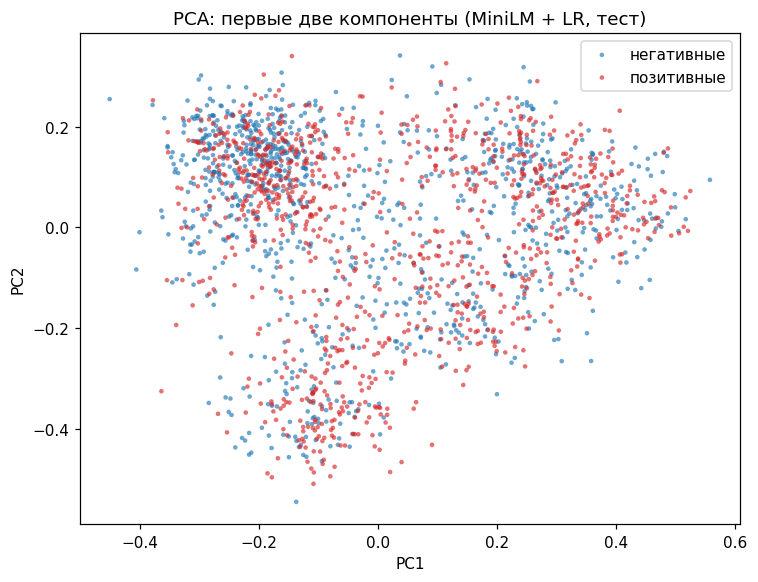

In [11]:
dense_features = {
    "Word2Vec + LR": (X_train_w2v, X_test_w2v),
    "MiniLM + LR": (X_train_mm, X_test_mm),
}
A_train, A_test = dense_features[best_dense]

n_components = min(50, A_train.shape[1], len(A_train) - 1)
pca = PCA(n_components=n_components, random_state=SEED).fit(A_train)
print(f"Метод: {best_dense}; компонент PCA: {n_components} из {A_train.shape[1]}")
print(f"Суммарная объясненная дисперсия: {pca.explained_variance_ratio_.sum():.4f}")

if len(y_test) > 2000:
    sel, _ = train_test_split(np.arange(len(y_test)), train_size=2000,
                              stratify=y_test, random_state=SEED)
    sel = np.sort(sel)
else:
    sel = np.arange(len(y_test))
print(f"Объектов теста для проекций: {len(sel)} (стратифицированно, seed {SEED})")
Z_test = pca.transform(A_test[sel])
y_sel = y_test[sel]

CLASS_COLORS = {0: "#1f77b4", 1: "#d62728"}
CLASS_LABELS = {0: "негативные", 1: "позитивные"}

fig, ax = plt.subplots(figsize=(7, 5.4))
for label in (0, 1):
    mask = y_sel == label
    ax.scatter(Z_test[mask, 0], Z_test[mask, 1], s=9, alpha=0.65,
               color=CLASS_COLORS[label], label=CLASS_LABELS[label], edgecolors="none")
ax.set_title(f"PCA: первые две компоненты ({best_dense}, тест)")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend()
plt.tight_layout()
plt.show()

t-SNE завершен за 4 с


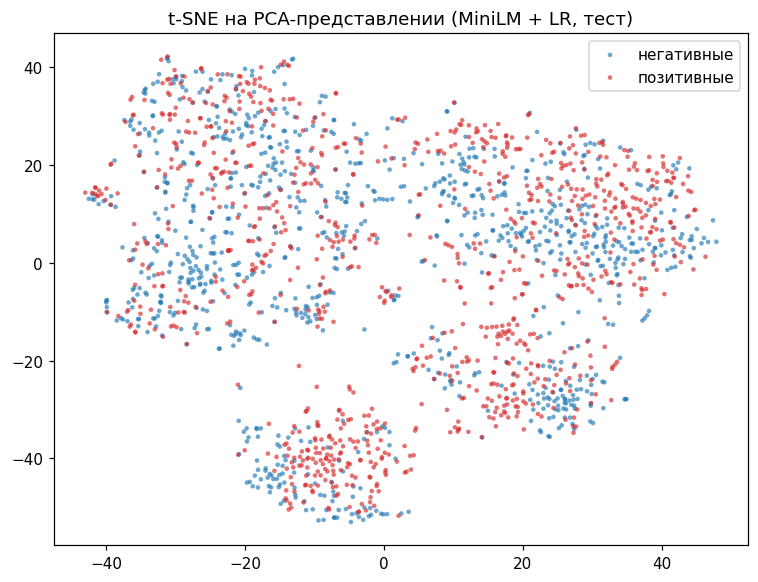

In [12]:
t0 = time.perf_counter()
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED)
T_test = tsne.fit_transform(Z_test)
print(f"t-SNE завершен за {time.perf_counter() - t0:.0f} с")

fig, ax = plt.subplots(figsize=(7, 5.4))
for label in (0, 1):
    mask = y_sel == label
    ax.scatter(T_test[mask, 0], T_test[mask, 1], s=9, alpha=0.65,
               color=CLASS_COLORS[label], label=CLASS_LABELS[label], edgecolors="none")
ax.set_title(f"t-SNE на PCA-представлении ({best_dense}, тест)")
ax.legend()
plt.tight_layout()
plt.show()

/home/vaiforic/orca/workspaces/dataforge/bulb-NeNet-and-modern-approaches/venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP завершен за 17 с


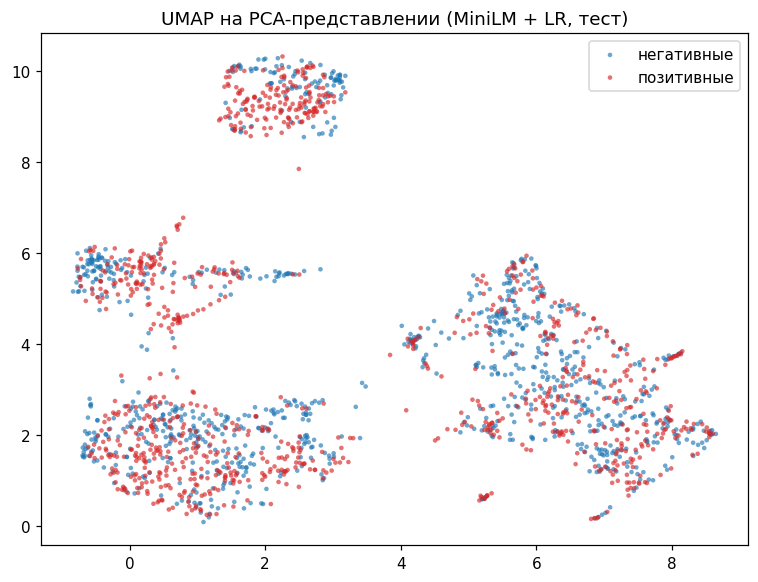

In [13]:
import umap

t0 = time.perf_counter()
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED)
U_test = reducer.fit_transform(Z_test)
print(f"UMAP завершен за {time.perf_counter() - t0:.0f} с")

fig, ax = plt.subplots(figsize=(7, 5.4))
for label in (0, 1):
    mask = y_sel == label
    ax.scatter(U_test[mask, 0], U_test[mask, 1], s=9, alpha=0.65,
               color=CLASS_COLORS[label], label=CLASS_LABELS[label], edgecolors="none")
ax.set_title(f"UMAP на PCA-представлении ({best_dense}, тест)")
ax.legend()
plt.tight_layout()
plt.show()

### Интерпретация проекций

- Классы тональности на всех трех диаграммах заметно **перекрываются**: одни и те же области
  содержат и позитивные, и негативные отзывы.
- На диаграммах видны локальные сгустки и разреженные области, но их семантика по самим
  проекциям не устанавливается: цвет точек несет только метку класса, а тематические или
  структурные объяснения сгустков (похожие товары, устойчивые формулировки) остаются
  непроверенными гипотезами — для их подтверждения нужен анализ текстов самих объектов.
- Отдельные удаленные от основной массы точки — кандидаты в выбросы; связывать их с
  конкретной причиной (короткие тексты, редкие слова) без разбора этих объектов было бы
  спекуляцией.
- Перекрытие или кластерность в 2D **не доказывает** и не опровергает линейную разделимость
  в исходном пространстве: t-SNE и UMAP искажают глобальные расстояния, а PCA показывает
  лишь два главных направления дисперсии.
- Проекции носят разведочный характер и построены на тестовых объектах: по ним **нельзя**
  подстраивать модели или выбирать методы — это утечка тестовых данных.

## 9. Сохранение результатов и выводы <a id="sec-9"></a>

Сохраняются: обученные векторизатор и логистические регрессии (TF-IDF и лучший плотный
метод вместе со стандартизатором), метаданные источника и представлений, идентификаторы
разбиения и кэш эмбеддингов. Все артефакты — стандартные форматы (pickle, npz, parquet,
JSON), пригодные для внешней загрузки и проверки.

In [14]:
import pickle

tfidf_bundle = {
    "vectorizer": tfidf,
    "classifier": clf_tfidf,
    "method": "tfidf",
    "source": SOURCE_REPO,
    "revision": SOURCE_REVISION,
    "seed": SEED,
}
with open(MODELS_DIR / "amazon_tfidf_model.pkl", "wb") as f:
    pickle.dump(tfidf_bundle, f)

dense_bundle = {"method": best_dense, "scaler": None, "classifier": None,
                "source": SOURCE_REPO, "revision": SOURCE_REVISION, "seed": SEED}
if best_dense == "MiniLM + LR":
    dense_bundle.update({"model_name": MINILM_NAME, "revision": MINILM_REVISION,
                         "batch_size": 32, "max_seq_length": int(minilm.max_seq_length),
                         "scaler": scaler_mm, "classifier": clf_mm})
else:
    dense_bundle.update({"model_name": W2V_NAME,
                         "token_row": token_row, "doc_vector_matrix": w2v_matrix,
                         "tokenizer_pattern": TOKEN_RE.pattern,
                         "scaler": scaler_w2v, "classifier": clf_w2v})
with open(MODELS_DIR / "amazon_dense_model.pkl", "wb") as f:
    pickle.dump(dense_bundle, f)

metrics_metadata = {
    "task": "amazon_polarity text representations",
    "source": SOURCE_REPO,
    "source_revision": SOURCE_REVISION,
    "sample": {"train_selected": 8000, "test_selected": 2000, "seed": SEED,
               "split": {"train": int(len(train_df)), "validation": int(len(val_df)),
                         "test": int(len(test_df))},
               "exclusions": {"empty": int(n_empty_removed), "train_duplicates": int(n_dup_train),
                              "cross_split_overlap": int(n_overlap), "test_duplicates": int(n_dup_test)}},
    "models": {"tfidf": {"vectorizer": "TfidfVectorizer(1-2, 10000)",
                          "classifier": "LogisticRegression(C=1)",
                          "validation": tfidf_val, "test": classification_metrics(
                              y_test, test_scores["TF-IDF + LR"]),
                          "seconds_extract": round(t_tfidf_extract, 2),
                          "seconds_fit": round(t_tfidf_fit, 2)},
               "word2vec": {"model": W2V_NAME,
                             "classifier": "LogisticRegression(C=1) на StandardScaler",
                             "validation": w2v_val, "test": classification_metrics(
                                 y_test, test_scores["Word2Vec + LR"]),
                             "coverage": {"tokens_total": int(tokens_total),
                                          "tokens_known": int(tokens_known),
                                          "token_coverage_ratio": round(tokens_known / tokens_total, 4),
                                          "documents_zero_vector": int(zero_docs),
                                          "documents_with_known_words": int(known_doc.sum())},
                             "seconds_extract": round(t_w2v_extract, 1),
                             "seconds_fit": round(t_w2v_fit, 2)},
               "minilm": {"model": MINILM_NAME, "revision": MINILM_REVISION,
                           "batch_size": 32, "max_seq_length": 256,
                           "truncation_fraction": round(frac_truncated, 4),
                           "classifier": "LogisticRegression(C=1) на StandardScaler",
                           "validation": minilm_val, "test": classification_metrics(
                               y_test, test_scores["MiniLM + LR"]),
                           "seconds_extract": round(t_minilm_extract, 1),
                           "seconds_fit": round(t_mm_fit, 2)}},
    "best_dense_method": best_dense,
    "projections": {"method": best_dense, "pca_components": int(n_components),
                     "explained_variance_ratio": round(float(pca.explained_variance_ratio_.sum()), 4),
                     "test_objects": int(len(sel)), "seed": SEED},
    "artifacts": {
        "splits": "data/processed/amazon_splits.parquet",
        "w2v_cache": "data/processed/amazon_w2v_docvectors.npz",
        "minilm_cache": "data/processed/amazon_minilm_embeddings.npz",
        "tfidf_model": "models/amazon_tfidf_model.pkl",
        "dense_model": "models/amazon_dense_model.pkl",
    },
    "environment": {k: str(v) for k, v in versions["версия"].to_dict().items()},
}
metadata_path = MODELS_DIR / "amazon_text_metadata.json"
metadata_path.write_text(json.dumps(metrics_metadata, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("Метаданные сохранены:", metadata_path)
print("Модели сохранены:", MODELS_DIR / "amazon_tfidf_model.pkl", "и", MODELS_DIR / "amazon_dense_model.pkl")

Метаданные сохранены: /home/vaiforic/orca/workspaces/dataforge/bulb-NeNet-and-modern-approaches/models/amazon_text_metadata.json
Модели сохранены: /home/vaiforic/orca/workspaces/dataforge/bulb-NeNet-and-modern-approaches/models/amazon_tfidf_model.pkl и /home/vaiforic/orca/workspaces/dataforge/bulb-NeNet-and-modern-approaches/models/amazon_dense_model.pkl


In [15]:
print("=== Сводка фактических результатов ===")
print("Лучший плотный метод по валидации:", best_dense)
display(val_table.style.format("{:.4f}").set_caption("Валидация (6 400 / 1 600)"))
display(test_table.style.format("{:.4f}").set_caption("Официальное тестовое подмножество (2 000)"))
print(f"PCA: {n_components} компонент, объяснено {pca.explained_variance_ratio_.sum():.1%} дисперсии")
print(f"MiniLM обрезает {frac_truncated:.1%} текстов на {minilm.max_seq_length} wordpiece-токенах")

=== Сводка фактических результатов ===
Лучший плотный метод по валидации: MiniLM + LR


,accuracy,roc_auc,f1
TF-IDF + LR,0.8706,0.9427,0.8674
Word2Vec + LR,0.8362,0.9143,0.8350
MiniLM + LR,0.8488,0.9259,0.8478


,accuracy,roc_auc,f1
TF-IDF + LR,0.8710,0.9422,0.8686
Word2Vec + LR,0.8415,0.9149,0.8367
MiniLM + LR,0.8515,0.9251,0.8514


PCA: 50 компонент, объяснено 52.2% дисперсии
MiniLM обрезает 0.1% текстов на 256 wordpiece-токенах


### Выводы

- Итоговые числа всех методов приведены в таблицах выше; они получены фактическим
  выполнением этого ноутбука и относятся к подмножеству 10 000 отзывов.
- TF-IDF с униграммами и биграммами — сильная базовая линия для коротких отзывов: она
  использует явные маркеры тональности и отрицания. Плотные представления конкурируют с
  ней за счет обобщения на синонимичные формулировки.
- Word2Vec-усреднение проигрывает контекстным эмбеддингам: усреднение теряет порядок слов
  и контекст отрицания. Фактические покрытие словаря Google News и число документов без
  единого известного слова напечатаны выше (в этом прогоне таких документов 0, нулевых
  векторов нет — все документы усредняют хотя бы одно известное слово).
- MiniLM кодирует весь отзыв как одно предложение в 384-мерное пространство; ограничение
  256 wordpiece-токенов затрагивает долю длинных отзывов, напечатанную выше, — для них
  хвост текста не влияет на эмбеддинг.
- Проекции показывают перекрытие классов и локальные сгустки; это разведочная картина,
  а не доказательство разделимости (см. раздел 8).
- Выбор лучшего плотного метода сделан только по валидации; тест использован один раз для
  финальной оценки всех трех представлений.